# Unit19_Example_Reactor_Kinetics | PINN 進階應用：非等溫反應器動態與活化能辨識

本 Notebook 以 **TensorFlow/Keras 從零實作一個物理資訊神經網路(PINN)**，求解反應工程中**最具挑戰性**的問題之一：**非等溫批次反應器的耦合非線性動態**。此問題：

- 是**耦合非線性常微分方程系統**（質量平衡 + 能量平衡 + Arrhenius 動力學）
- **沒有解析解**，以高精度數值解器 `scipy.solve_ivp` 作為驗證基準
- 反問題即經典的**動力學參數估計**——從稀疏量測**辨識活化能**

## 目標
- 以**單一網路、雙輸出** PINN 同時求解濃度 $c(\tau)$ 與溫度 $\theta(\tau)$
- 處理 **Arrhenius 指數非線性** 與質能耦合
- **正問題**：已知動力學參數，求解反應器動態，與 `solve_ivp` 比對
- **反問題**：由稀疏帶雜訊量測**辨識無因次活化能** $\gamma$ （反應工程最重要的反問題）

這是 Unit19 PINN 系列的**進階**範例，從單一方程進展到**耦合非線性系統**。

---
### 0. 環境設定
- 本範例以數值解器產生參考解與合成資料，無需下載外部資料集。
- 使用 TensorFlow/Keras 從零實作 PINN，資料量小，可在 Colab 或本地 CPU 環境執行。

In [1]:
from pathlib import Path
import tensorflow as tf
import os

# ========================================
# 路徑設定 (兼容 Colab 與 Local)
# ========================================
UNIT_OUTPUT_DIR = 'P4_Unit19_Example_Reactor_Kinetics'
SOURCE_DATA_DIR = 'reactor'

try:
    from google.colab import drive
    IN_COLAB = True
    print("✓ 偵測到 Colab 環境，準備掛載 Google Drive...")
    drive.mount('/content/drive', force_remount=True)
except ImportError:
    IN_COLAB = False
    print("✓ 偵測到 Local 環境")

if IN_COLAB:
    shortcut_path = '/content/ChemE-3590'
    try:
        os.remove(shortcut_path)
    except FileNotFoundError:
        pass
    source_path = Path('/content/drive/My Drive/Colab Notebooks/ChemE-3590')
    os.symlink(source_path, shortcut_path)
    NOTEBOOK_DIR = Path(shortcut_path) / 'Part_4' / 'Unit19'
else:
    NOTEBOOK_DIR = Path.cwd()

OUTPUT_DIR = NOTEBOOK_DIR / 'outputs' / UNIT_OUTPUT_DIR
MODEL_DIR = OUTPUT_DIR / 'models'
FIG_DIR = OUTPUT_DIR / 'figs'
for d in (OUTPUT_DIR, MODEL_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

print(f"\n✓ Notebook工作目錄: {NOTEBOOK_DIR}")
print(f"✓ 結果輸出目錄: {OUTPUT_DIR}")
print(f"✓ 模型輸出目錄: {MODEL_DIR}")
print(f"✓ 圖檔輸出目錄: {FIG_DIR}")

print(f"\nTensorFlow Version: {tf.__version__}")
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"✓ 偵測到 GPU：{gpus[0].name}")
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
else:
    print("△ 未偵測到 GPU，將使用 CPU（本範例資料量小，CPU 即可）")

✓ 偵測到 Local 環境

✓ Notebook工作目錄: d:\MyGit\ChemE-3590\Part_4\Unit19
✓ 結果輸出目錄: d:\MyGit\ChemE-3590\Part_4\Unit19\outputs\P4_Unit19_Example_Reactor_Kinetics
✓ 模型輸出目錄: d:\MyGit\ChemE-3590\Part_4\Unit19\outputs\P4_Unit19_Example_Reactor_Kinetics\models
✓ 圖檔輸出目錄: d:\MyGit\ChemE-3590\Part_4\Unit19\outputs\P4_Unit19_Example_Reactor_Kinetics\figs

TensorFlow Version: 2.10.1
✓ 偵測到 GPU：/physical_device:GPU:0


---
### 1. 導入必要套件

In [2]:
# 基礎套件
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import warnings
warnings.filterwarnings('ignore')

# TensorFlow / Keras
from tensorflow import keras
from tensorflow.keras import layers

print(f"TensorFlow版本: {tf.__version__}")
print(f"Keras版本: {keras.__version__}")

# 設定隨機種子以確保結果可重現
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

plt.rcParams['axes.unicode_minus'] = False

TensorFlow版本: 2.10.1
Keras版本: 2.10.0


---
### 2. 問題定義：非等溫批次反應器

考慮一個攪拌均勻的**批次反應器**，內部進行放熱的一級不可逆反應 $A \rightarrow B$ ，並以冷卻盤管移除反應熱。以**質量平衡**與**能量平衡**描述其動態：

$$
\frac{dC_A}{dt} = -k(T)\,C_A, \qquad \rho C_p \frac{dT}{dt} = (-\Delta H_r)\,k(T)\,C_A - \frac{UA}{V}(T - T_c)
$$

反應速率常數遵循 **Arrhenius 定律** $k(T) = k_0 \exp\!\left(-E/RT\right)$ ，其中 $E$ 是**活化能**。

### 2.1 無因次化

引入無因次變數：濃度 $c = C_A/C_{A0}$ 、溫度 $\theta = (T-T_0)/T_0$ 、時間 $\tau = t/t_{\mathrm{ref}}$ ，可得**無因次耦合方程**：

$$
\frac{dc}{d\tau} = -\mathrm{Da}\,c\,e^{\frac{\gamma\theta}{1+\theta}}, \qquad
\frac{d\theta}{d\tau} = B\,\mathrm{Da}\,c\,e^{\frac{\gamma\theta}{1+\theta}} - \beta\,\theta
$$

初始條件 $c(0)=1,\ \theta(0)=0$ 。四個無因次群的物理意義：

| 符號 | 名稱 | 物理意義 |
|---|---|---|
| $\mathrm{Da}$ | Damköhler 數 | 反應速率 / 特徵時間尺度 |
| $\gamma$ | 無因次活化能 | $E/(R T_0)$ ，溫度敏感度 |
| $B$ | 放熱參數 | 絕熱溫升幅度 |
| $\beta$ | 冷卻係數 | 移熱能力 |

本範例取 $\mathrm{Da}=2.0,\ \gamma=3.0,\ B=1.0,\ \beta=6.0$ 。放熱使溫度先上升，隨反應物耗盡與冷卻作用，溫度再回落——典型的**放熱反應熱點(hot spot)** 行為。

> [!NOTE]
> 此方程**沒有解析解**（Arrhenius 指數項使其強非線性）。我們以高精度數值解器 `scipy.integrate.solve_ivp`（RK45，嚴格容差）作為「真實解」基準，這也示範了 PINN 與傳統數值方法的互補。

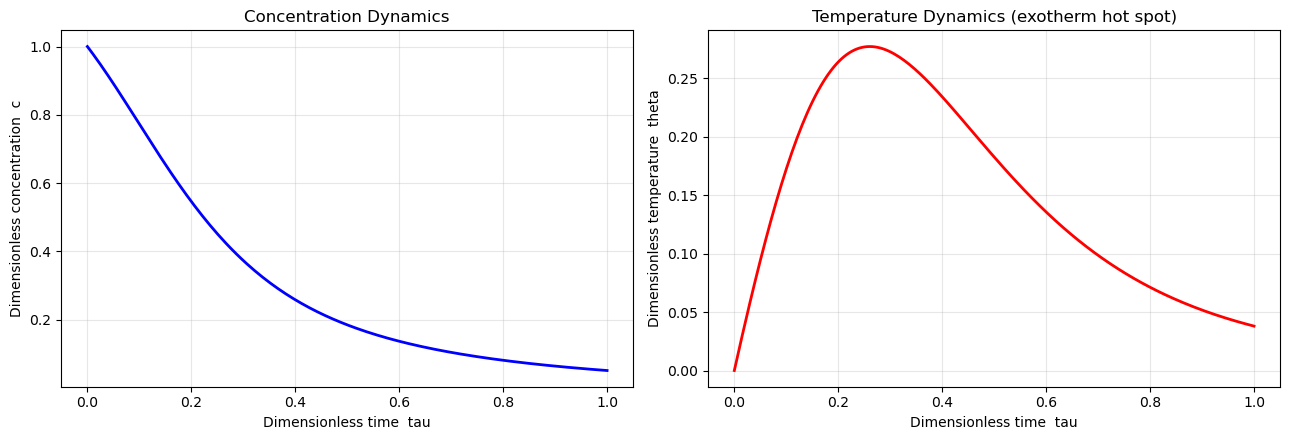

參數: Da=2.0, gamma=3.0, B=1.0, beta=6.0
最終轉化: 1 - c(1) = 0.949
最高無因次溫度 theta_max = 0.2770 @ tau = 0.261
c(0.5) = 0.1830, theta(0.5) = 0.1813


In [3]:
# 無因次動力學參數真值
Da, GAMMA_TRUE, Bq, BETA = 2.0, 3.0, 1.0, 6.0

def reactor_rhs(tau, y, gamma=GAMMA_TRUE):
    c, th = y
    rate = Da * c * np.exp(gamma * th / (1.0 + th))
    return [-rate, Bq * rate - BETA * th]

# 以高精度數值解器求參考解
ref = solve_ivp(reactor_rhs, [0, 1], [1.0, 0.0], dense_output=True,
                rtol=1e-10, atol=1e-12, max_step=0.002)
tau_plot = np.linspace(0, 1, 200)
Y_ref = ref.sol(tau_plot)       # [c; theta]
c_ref, th_ref = Y_ref[0], Y_ref[1]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(tau_plot, c_ref, 'b-', lw=2)
axes[0].set_xlabel('Dimensionless time  tau'); axes[0].set_ylabel('Dimensionless concentration  c')
axes[0].set_title('Concentration Dynamics'); axes[0].grid(alpha=0.3)
axes[1].plot(tau_plot, th_ref, 'r-', lw=2)
axes[1].set_xlabel('Dimensionless time  tau'); axes[1].set_ylabel('Dimensionless temperature  theta')
axes[1].set_title('Temperature Dynamics (exotherm hot spot)'); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / 'reference_dynamics.png', dpi=120)
plt.show()

print(f"參數: Da={Da}, gamma={GAMMA_TRUE}, B={Bq}, beta={BETA}")
print(f"最終轉化: 1 - c(1) = {1 - c_ref[-1]:.3f}")
print(f"最高無因次溫度 theta_max = {th_ref.max():.4f} @ tau = {tau_plot[th_ref.argmax()]:.3f}")
print(f"c(0.5) = {c_ref[100]:.4f}, theta(0.5) = {th_ref[100]:.4f}")

### 2.4 活化能 $\gamma$ 對反應器動態的影響

活化能 $\gamma$ 決定反應對溫度的敏感度，直接影響熱點高度與反應快慢。下圖比較 $\gamma = 2, 3, 4$ 時的濃度與溫度動態： $\gamma$ 越大，溫度對速率的正回饋越強，**熱點越高、反應越快**。這個明顯的差異正說明了為何能從動態量測反推 $\gamma$ （反問題的可辨識性基礎）。

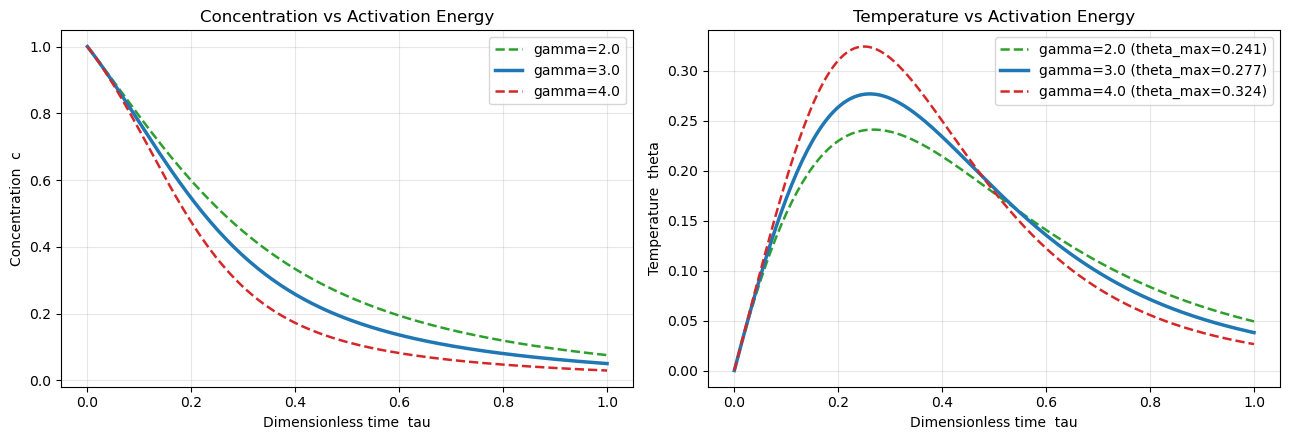

gamma=2.0: theta_max=0.2413, conversion 1-c(1)=0.924
gamma=3.0: theta_max=0.2770, conversion 1-c(1)=0.949
gamma=4.0: theta_max=0.3245, conversion 1-c(1)=0.970


In [4]:
# 比較不同活化能 gamma 下的反應器動態
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
colors = {2.0: '#2ca02c', 3.0: '#1f77b4', 4.0: '#d62728'}
for gval in [2.0, 3.0, 4.0]:
    solg = solve_ivp(lambda t, y: reactor_rhs(t, y, gval), [0, 1], [1.0, 0.0],
                     dense_output=True, rtol=1e-10, atol=1e-12, max_step=0.002)
    Yg = solg.sol(tau_plot)
    style = '-' if gval == GAMMA_TRUE else '--'
    lw = 2.5 if gval == GAMMA_TRUE else 1.8
    axes[0].plot(tau_plot, Yg[0], style, color=colors[gval], lw=lw, label=f'gamma={gval}')
    axes[1].plot(tau_plot, Yg[1], style, color=colors[gval], lw=lw,
                 label=f'gamma={gval} (theta_max={Yg[1].max():.3f})')
axes[0].set_xlabel('Dimensionless time  tau'); axes[0].set_ylabel('Concentration  c')
axes[0].set_title('Concentration vs Activation Energy'); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].set_xlabel('Dimensionless time  tau'); axes[1].set_ylabel('Temperature  theta')
axes[1].set_title('Temperature vs Activation Energy'); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / 'gamma_sensitivity.png', dpi=120)
plt.show()

for gval in [2.0, 3.0, 4.0]:
    solg = solve_ivp(lambda t, y: reactor_rhs(t, y, gval), [0, 1], [1.0, 0.0],
                     dense_output=True, rtol=1e-10, atol=1e-12, max_step=0.002)
    Yg = solg.sol(tau_plot)
    print(f"gamma={gval}: theta_max={Yg[1].max():.4f}, conversion 1-c(1)={1-Yg[0,-1]:.3f}")

---
### 3. 建立 PINN 模型（單網路、雙輸出）

反應器有**兩個狀態變數** $c$ 與 $\theta$ ，兩者由同一個時間 $\tau$ 驅動且彼此耦合。我們用**單一網路、兩個輸出**同時表示 $[\,\hat{c}_\theta(\tau),\ \hat{\theta}_\theta(\tau)\,]$ ，共享隱藏層以學習耦合關係。網路採 5 個隱藏層、每層 32 個神經元、 $\tanh$ 激活。

In [5]:
def build_pinn(n_hidden=5, n_units=32, seed=SEED):
    """以 tau 為輸入，輸出 [c, theta] 雙狀態的 PINN"""
    init = keras.initializers.GlorotNormal(seed=seed)
    inp = keras.Input(shape=(1,), name='tau')
    h = inp
    for i in range(n_hidden):
        h = layers.Dense(n_units, activation='tanh',
                         kernel_initializer=init, name=f'hidden_{i+1}')(h)
    out = layers.Dense(2, kernel_initializer=init, name='c_theta')(h)
    return keras.Model(inp, out, name='PINN_Reactor')

pinn_demo = build_pinn()
pinn_demo.summary()

Model: "PINN_Reactor"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 tau (InputLayer)            [(None, 1)]               0         
                                                                 
 hidden_1 (Dense)            (None, 32)                64        
                                                                 
 hidden_2 (Dense)            (None, 32)                1056      
                                                                 
 hidden_3 (Dense)            (None, 32)                1056      
                                                                 
 hidden_4 (Dense)            (None, 32)                1056      
                                                                 
 hidden_5 (Dense)            (None, 32)                1056      
                                                                 
 c_theta (Dense)             (None, 2)                

---
### 4. 正問題：耦合非線性殘差

**正問題**：已知所有參數，求解反應器動態。兩條 ODE 各有一個殘差：

$$
r_c = \frac{d\hat{c}}{d\tau} + \mathrm{Da}\,\hat{c}\,e^{\frac{\gamma\hat{\theta}}{1+\hat{\theta}}}, \qquad
r_\theta = \frac{d\hat{\theta}}{d\tau} - B\,\mathrm{Da}\,\hat{c}\,e^{\frac{\gamma\hat{\theta}}{1+\hat{\theta}}} + \beta\,\hat{\theta}
$$

用一個 `persistent=True` 的 `tf.GradientTape` 一次取得 $d\hat{c}/d\tau$ 與 $d\hat{\theta}/d\tau$ 。

In [6]:
def reactor_residual(model, tau, gamma):
    """返回質量與能量平衡殘差 (rc, rth)"""
    with tf.GradientTape(persistent=True) as g:
        g.watch(tau)
        out = model(tau)
        c = out[:, 0:1]
        th = out[:, 1:2]
    dc = g.gradient(c, tau)
    dth = g.gradient(th, tau)
    del g
    rate = Da * c * tf.exp(gamma * th / (1.0 + th))
    rc = dc + rate
    rth = dth - Bq * rate + BETA * th
    return rc, rth

# 配點與初始條件點
N_COLLOC = 200
tau_colloc = tf.convert_to_tensor(
    np.linspace(0, 1, N_COLLOC).reshape(-1, 1).astype('float32'))
tau_ic = tf.constant([[0.0]], dtype=tf.float32)   # c(0)=1, theta(0)=0

print(f"配點數量: {N_COLLOC}，範圍 tau ∈ [0, 1]")

配點數量: 200，範圍 tau ∈ [0, 1]


### 4.1 訓練正問題 PINN

總損失 = 兩條 ODE 殘差 + 初始條件（IC 加權 20 倍）：

$$
\mathcal{L} = \mathcal{L}_{r_c} + \mathcal{L}_{r_\theta} + 20\big(|\hat{c}(0)-1|^2 + |\hat{\theta}(0)|^2\big)
$$

耦合非線性系統較難收斂，採用**學習率分段衰減**（ $10^{-3}\to 3\times10^{-4}\to 10^{-4}$ ）。

In [7]:
pinn_fwd = build_pinn()
lr_sched = keras.optimizers.schedules.PiecewiseConstantDecay(
    boundaries=[8000, 14000], values=[1e-3, 3e-4, 1e-4])
opt_fwd = keras.optimizers.Adam(learning_rate=lr_sched)
W_IC = 20.0

@tf.function
def train_step_forward():
    with tf.GradientTape() as tape:
        rc, rth = reactor_residual(pinn_fwd, tau_colloc, GAMMA_TRUE)
        loss_pde = tf.reduce_mean(tf.square(rc)) + tf.reduce_mean(tf.square(rth))
        o0 = pinn_fwd(tau_ic)
        loss_ic = tf.square(o0[0, 0] - 1.0) + tf.square(o0[0, 1] - 0.0)
        loss = loss_pde + W_IC * loss_ic
    grads = tape.gradient(loss, pinn_fwd.trainable_variables)
    opt_fwd.apply_gradients(zip(grads, pinn_fwd.trainable_variables))
    return loss, loss_pde, loss_ic

EPOCHS_FWD = 18000
for ep in range(EPOCHS_FWD + 1):
    loss, lp, lic = train_step_forward()
    if ep % 2000 == 0:
        print(f"Epoch {ep:5d} | total={float(loss):.3e} | pde={float(lp):.3e} | ic={float(lic):.3e}")

Epoch     0 | total=2.048e+01 | pde=4.812e-01 | ic=1.000e+00
Epoch  2000 | total=2.224e-04 | pde=2.219e-04 | ic=2.294e-08
Epoch  4000 | total=3.224e-04 | pde=3.208e-04 | ic=7.712e-08
Epoch  6000 | total=1.942e-04 | pde=1.718e-04 | ic=1.119e-06
Epoch  8000 | total=1.210e-04 | pde=1.201e-04 | ic=4.570e-08
Epoch 10000 | total=8.514e-05 | pde=6.232e-05 | ic=1.141e-06
Epoch 12000 | total=1.271e-04 | pde=1.111e-04 | ic=7.989e-07
Epoch 14000 | total=3.831e-05 | pde=3.829e-05 | ic=6.665e-10
Epoch 16000 | total=9.684e-06 | pde=9.495e-06 | ic=9.461e-09
Epoch 18000 | total=9.847e-06 | pde=7.843e-06 | ic=1.002e-07


### 4.2 正問題結果與數值解比較

PINN 在**不使用任何資料**下，僅憑耦合 ODE 與初始條件，重建了 $c(\tau)$ 與 $\theta(\tau)$ 。我們與 `solve_ivp` 參考解比對。

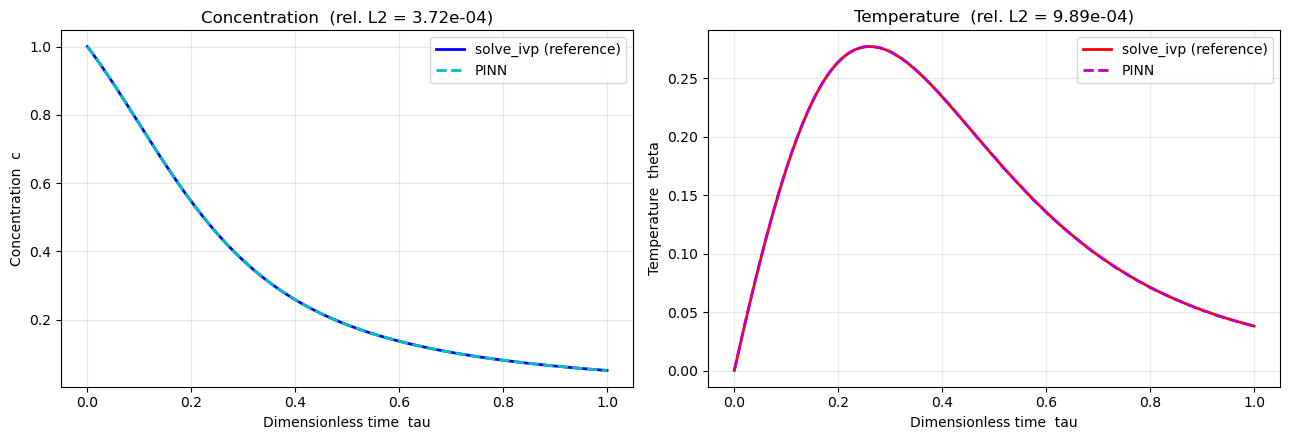

濃度 c 相對 L2 誤差: 3.717e-04
溫度 theta 相對 L2 誤差: 9.886e-04
PINN theta_max = 0.2770 (參考 0.2770)


In [8]:
tau_t = tf.convert_to_tensor(tau_plot.reshape(-1, 1).astype('float32'))
out_fwd = pinn_fwd(tau_t).numpy()
c_pinn, th_pinn = out_fwd[:, 0], out_fwd[:, 1]

rel_l2_c = np.linalg.norm(c_pinn - c_ref) / np.linalg.norm(c_ref)
rel_l2_th = np.linalg.norm(th_pinn - th_ref) / np.linalg.norm(th_ref)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(tau_plot, c_ref, 'b-', lw=2, label='solve_ivp (reference)')
axes[0].plot(tau_plot, c_pinn, 'c--', lw=2, label='PINN')
axes[0].set_xlabel('Dimensionless time  tau'); axes[0].set_ylabel('Concentration  c')
axes[0].set_title(f'Concentration  (rel. L2 = {rel_l2_c:.2e})')
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(tau_plot, th_ref, 'r-', lw=2, label='solve_ivp (reference)')
axes[1].plot(tau_plot, th_pinn, 'm--', lw=2, label='PINN')
axes[1].set_xlabel('Dimensionless time  tau'); axes[1].set_ylabel('Temperature  theta')
axes[1].set_title(f'Temperature  (rel. L2 = {rel_l2_th:.2e})')
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / 'forward_result.png', dpi=120)
plt.show()

print(f"濃度 c 相對 L2 誤差: {rel_l2_c:.3e}")
print(f"溫度 theta 相對 L2 誤差: {rel_l2_th:.3e}")
print(f"PINN theta_max = {th_pinn.max():.4f} (參考 {th_ref.max():.4f})")

### 4.3 相圖與逐點誤差

**相圖(phase portrait)** 在 $c$-$\theta$ 平面上畫出系統軌跡，直觀呈現耦合動態：系統從初始點 $(1, 0)$ 出發，濃度下降的同時溫度先升後降，形成一條彎曲的軌跡。PINN 解（虛線）與參考解（實線）應完全重合。右圖為兩個狀態的逐點絕對誤差。

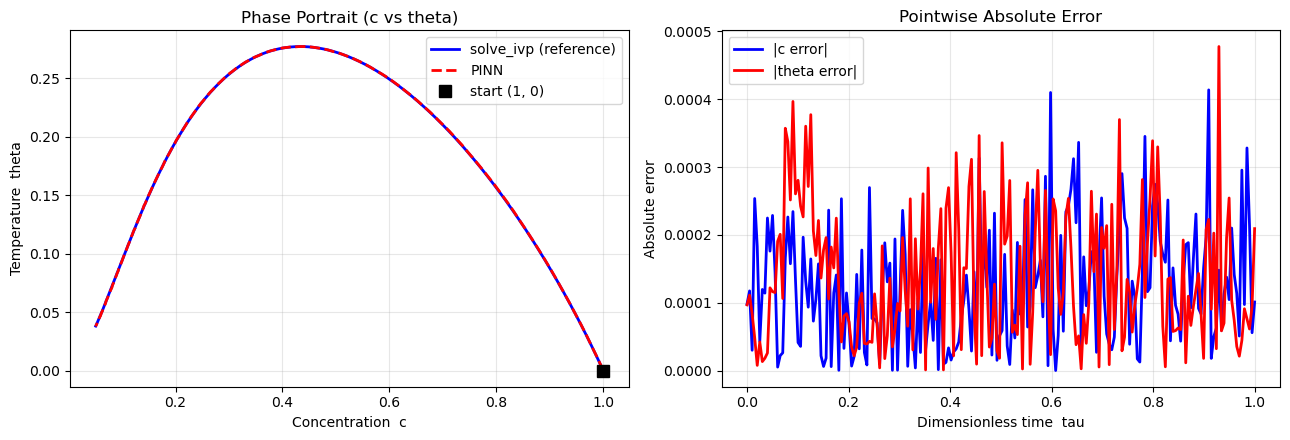

c   max abs error: 4.136e-04
theta max abs error: 4.774e-04


In [9]:
# 相圖 (c-theta 平面) 與逐點誤差
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(c_ref, th_ref, 'b-', lw=2, label='solve_ivp (reference)')
axes[0].plot(c_pinn, th_pinn, 'r--', lw=2, label='PINN')
axes[0].plot([1.0], [0.0], 'ks', ms=9, label='start (1, 0)')
axes[0].set_xlabel('Concentration  c'); axes[0].set_ylabel('Temperature  theta')
axes[0].set_title('Phase Portrait (c vs theta)'); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(tau_plot, np.abs(c_pinn - c_ref), 'b-', lw=2, label='|c error|')
axes[1].plot(tau_plot, np.abs(th_pinn - th_ref), 'r-', lw=2, label='|theta error|')
axes[1].set_xlabel('Dimensionless time  tau'); axes[1].set_ylabel('Absolute error')
axes[1].set_title('Pointwise Absolute Error'); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / 'forward_phase_error.png', dpi=120)
plt.show()

print(f"c   max abs error: {np.abs(c_pinn - c_ref).max():.3e}")
print(f"theta max abs error: {np.abs(th_pinn - th_ref).max():.3e}")

### 4.4 能量平衡：產熱與移熱

溫度的升降由能量平衡中兩項的競爭決定：**產熱項** $B\,\mathrm{Da}\,c\,e^{\gamma\theta/(1+\theta)}$ 與**移熱項** $\beta\theta$ 。當產熱 > 移熱時溫度上升；兩者相等時 $\mathrm{d}\theta/\mathrm{d}\tau=0$ ，達到**熱點峰**；之後移熱主導使溫度回落。下圖以參考解分解這兩項，驗證它們恰好在溫度峰值處交會。

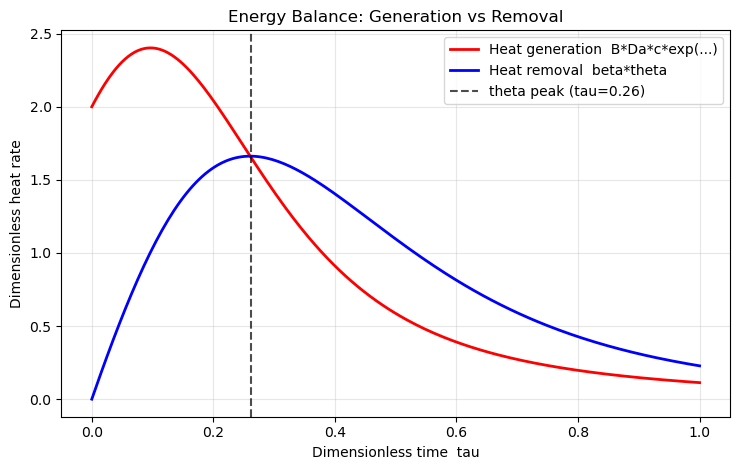

At theta peak (tau=0.261): generation=1.6577, removal=1.6621
(generation == removal at the peak, since d(theta)/d(tau)=0)


In [10]:
# 能量平衡分解：產熱 vs 移熱
rate_ref = Da * c_ref * np.exp(GAMMA_TRUE * th_ref / (1.0 + th_ref))
gen = Bq * rate_ref       # 產熱項
cool = BETA * th_ref      # 移熱項
peak_idx = th_ref.argmax()

fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.plot(tau_plot, gen, 'r-', lw=2, label='Heat generation  B*Da*c*exp(...)')
ax.plot(tau_plot, cool, 'b-', lw=2, label='Heat removal  beta*theta')
ax.axvline(tau_plot[peak_idx], color='k', ls='--', alpha=0.7,
           label=f'theta peak (tau={tau_plot[peak_idx]:.2f})')
ax.set_xlabel('Dimensionless time  tau'); ax.set_ylabel('Dimensionless heat rate')
ax.set_title('Energy Balance: Generation vs Removal'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / 'energy_balance.png', dpi=120)
plt.show()

print(f"At theta peak (tau={tau_plot[peak_idx]:.3f}): generation={gen[peak_idx]:.4f}, removal={cool[peak_idx]:.4f}")
print("(generation == removal at the peak, since d(theta)/d(tau)=0)")

---
### 5. 反問題：辨識活化能

**反問題**：在動力學研究中，**活化能** $E$ （無因次化為 $\gamma$ ）通常**未知**，需由實驗量測反推——這是反應工程**最核心的參數估計任務**。

本範例假設可在少數時間點量測濃度與溫度（帶雜訊），把 $\gamma$ 設為**可訓練變數**，與網路一起優化。

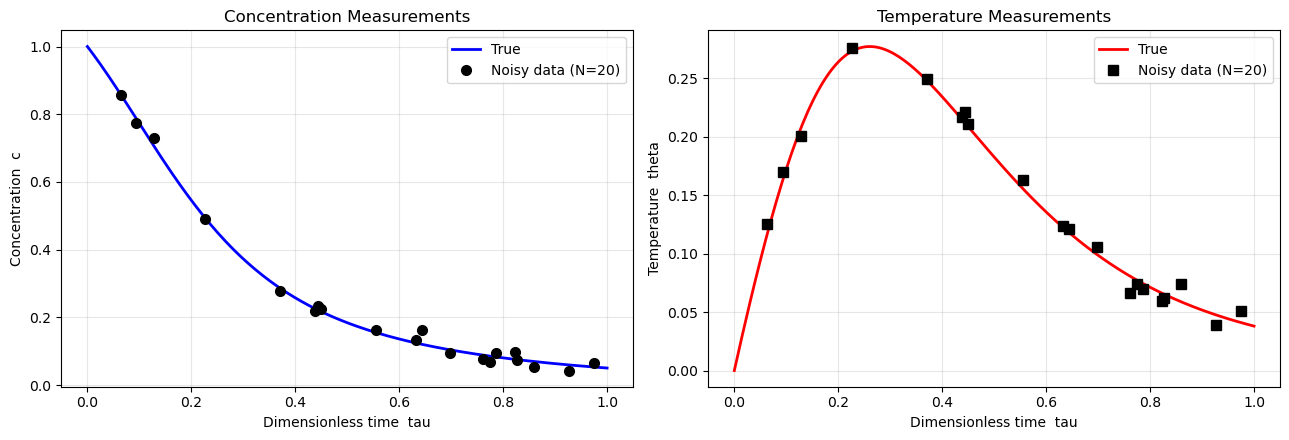

觀測資料點數: 20，濃度雜訊 0.02，溫度雜訊 0.01


In [11]:
# 產生稀疏帶雜訊的量測 (濃度與溫度)
rng = np.random.default_rng(SEED)
N_DATA = 20
tau_obs = np.sort(rng.uniform(0, 1, N_DATA))
Y_obs = ref.sol(tau_obs)
c_obs = Y_obs[0] + rng.normal(0, 0.02, N_DATA)
th_obs = Y_obs[1] + rng.normal(0, 0.01, N_DATA)

tau_obs_tf = tf.convert_to_tensor(tau_obs.reshape(-1, 1).astype('float32'))
c_obs_tf = tf.convert_to_tensor(c_obs.reshape(-1, 1).astype('float32'))
th_obs_tf = tf.convert_to_tensor(th_obs.reshape(-1, 1).astype('float32'))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(tau_plot, c_ref, 'b-', lw=2, label='True')
axes[0].plot(tau_obs, c_obs, 'ko', ms=7, label=f'Noisy data (N={N_DATA})')
axes[0].set_xlabel('Dimensionless time  tau'); axes[0].set_ylabel('Concentration  c')
axes[0].set_title('Concentration Measurements'); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(tau_plot, th_ref, 'r-', lw=2, label='True')
axes[1].plot(tau_obs, th_obs, 'ks', ms=7, label=f'Noisy data (N={N_DATA})')
axes[1].set_xlabel('Dimensionless time  tau'); axes[1].set_ylabel('Temperature  theta')
axes[1].set_title('Temperature Measurements'); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / 'inverse_data.png', dpi=120)
plt.show()

print(f"觀測資料點數: {N_DATA}，濃度雜訊 0.02，溫度雜訊 0.01")

### 5.1 訓練反問題 PINN

初始猜測 $\gamma_{\mathrm{init}}=1.5$ （真值 3.0）。損失同時包含資料項、含未知 $\gamma$ 的 ODE 殘差與初始條件。

In [12]:
pinn_inv = build_pinn()
gamma_var = tf.Variable(1.5, dtype=tf.float32, name='gamma')   # 待辨識的活化能
lr_sched_inv = keras.optimizers.schedules.PiecewiseConstantDecay(
    boundaries=[8000, 14000], values=[2e-3, 5e-4, 1e-4])
opt_inv = keras.optimizers.Adam(learning_rate=lr_sched_inv)

@tf.function
def train_step_inverse():
    with tf.GradientTape() as tape:
        out_d = pinn_inv(tau_obs_tf)
        loss_data = tf.reduce_mean(tf.square(out_d[:, 0:1] - c_obs_tf)) + \
                    tf.reduce_mean(tf.square(out_d[:, 1:2] - th_obs_tf))
        rc, rth = reactor_residual(pinn_inv, tau_colloc, gamma_var)
        loss_pde = tf.reduce_mean(tf.square(rc)) + tf.reduce_mean(tf.square(rth))
        o0 = pinn_inv(tau_ic)
        loss_ic = tf.square(o0[0, 0] - 1.0) + tf.square(o0[0, 1] - 0.0)
        loss = loss_data + loss_pde + W_IC * loss_ic
    var_list = pinn_inv.trainable_variables + [gamma_var]
    grads = tape.gradient(loss, var_list)
    opt_inv.apply_gradients(zip(grads, var_list))
    return loss, loss_data, loss_pde, gamma_var

EPOCHS_INV = 18000
gamma_history = []
for ep in range(EPOCHS_INV + 1):
    loss, ld, lp, gv = train_step_inverse()
    if ep % 300 == 0:
        gamma_history.append((ep, float(gv)))
    if ep % 2000 == 0:
        print(f"Epoch {ep:5d} | total={float(loss):.3e} | data={float(ld):.3e} | "
              f"pde={float(lp):.3e} | gamma={float(gv):.4f}")

gamma_pred = float(gamma_var)
print(f"\n✓ 辨識結果: gamma_pred = {gamma_pred:.4f}  (真值 gamma_true = {GAMMA_TRUE})")
print(f"  相對誤差: {abs(gamma_pred - GAMMA_TRUE)/GAMMA_TRUE*100:.2f}%")

Epoch     0 | total=2.066e+01 | data=1.420e-01 | pde=5.199e-01 | gamma=1.5020
Epoch  2000 | total=1.835e-03 | data=1.648e-03 | pde=1.866e-04 | gamma=2.2166
Epoch  4000 | total=1.295e-02 | data=5.116e-04 | pde=1.159e-02 | gamma=2.7641
Epoch  6000 | total=1.521e-02 | data=5.450e-04 | pde=1.280e-02 | gamma=2.8879
Epoch  8000 | total=4.211e-04 | data=2.936e-04 | pde=1.029e-04 | gamma=2.9241
Epoch 10000 | total=3.147e-04 | data=2.915e-04 | pde=2.250e-05 | gamma=2.9379
Epoch 12000 | total=3.220e-04 | data=2.902e-04 | pde=3.073e-05 | gamma=2.9513
Epoch 14000 | total=3.788e-04 | data=2.899e-04 | pde=5.750e-05 | gamma=2.9553
Epoch 16000 | total=2.965e-04 | data=2.897e-04 | pde=6.315e-06 | gamma=2.9554
Epoch 18000 | total=2.974e-04 | data=2.907e-04 | pde=6.449e-06 | gamma=2.9559

✓ 辨識結果: gamma_pred = 2.9559  (真值 gamma_true = 3.0)
  相對誤差: 1.47%


### 5.2 反問題結果：活化能 $\gamma$ 收斂

左圖顯示可訓練活化能 $\gamma$ 從初始猜測收斂到真值；右圖顯示辨識後 PINN 解與參考解、量測資料的吻合。

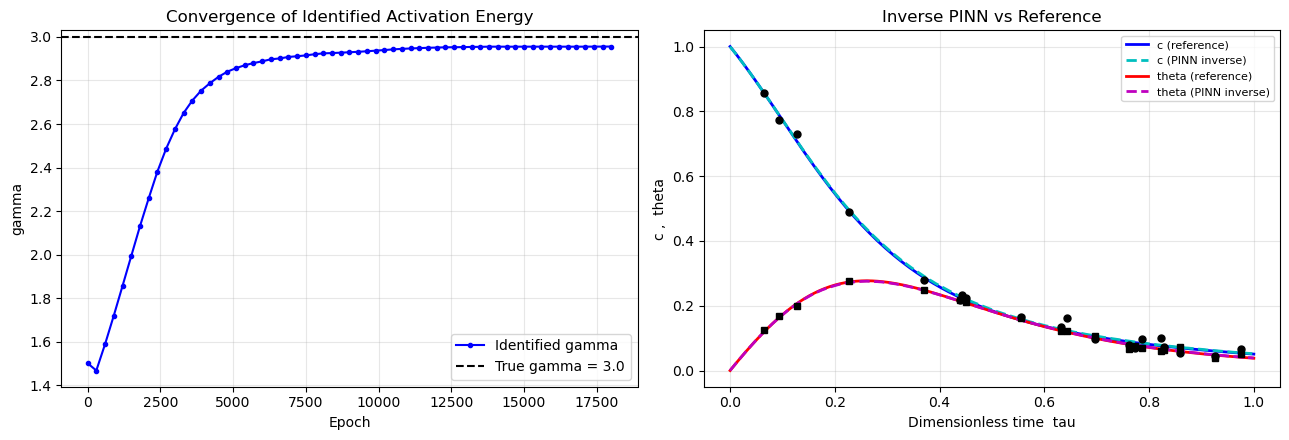

最終 gamma_pred = 2.9559 | gamma_true = 3.0


In [13]:
g_eps = np.array([h[0] for h in gamma_history])
g_vals = np.array([h[1] for h in gamma_history])
out_inv = pinn_inv(tau_t).numpy()
c_inv, th_inv = out_inv[:, 0], out_inv[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(g_eps, g_vals, 'b-o', ms=3, label='Identified gamma')
axes[0].axhline(GAMMA_TRUE, color='k', ls='--', label=f'True gamma = {GAMMA_TRUE}')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('gamma')
axes[0].set_title('Convergence of Identified Activation Energy')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(tau_plot, c_ref, 'b-', lw=2, label='c (reference)')
axes[1].plot(tau_plot, c_inv, 'c--', lw=2, label='c (PINN inverse)')
axes[1].plot(tau_plot, th_ref, 'r-', lw=2, label='theta (reference)')
axes[1].plot(tau_plot, th_inv, 'm--', lw=2, label='theta (PINN inverse)')
axes[1].plot(tau_obs, c_obs, 'ko', ms=5); axes[1].plot(tau_obs, th_obs, 'ks', ms=5)
axes[1].set_xlabel('Dimensionless time  tau'); axes[1].set_ylabel('c ,  theta')
axes[1].set_title('Inverse PINN vs Reference'); axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / 'inverse_result.png', dpi=120)
plt.show()

print(f"最終 gamma_pred = {gamma_pred:.4f} | gamma_true = {GAMMA_TRUE}")

---
### 6. 模型與結果儲存

In [14]:
# 儲存正問題與反問題 PINN 權重 (TensorFlow checkpoint 格式)
fwd_path = MODEL_DIR / 'pinn_reactor_forward'
inv_path = MODEL_DIR / 'pinn_reactor_inverse'
pinn_fwd.save_weights(str(fwd_path))
pinn_inv.save_weights(str(inv_path))

import json
results = {
    'gamma_true': GAMMA_TRUE,
    'gamma_pred': gamma_pred,
    'forward_rel_L2_c': float(rel_l2_c),
    'forward_rel_L2_theta': float(rel_l2_th),
    'gamma_rel_error_pct': float(abs(gamma_pred - GAMMA_TRUE)/GAMMA_TRUE*100),
    'params': {'Da': Da, 'B': Bq, 'beta': BETA},
}
with open(MODEL_DIR / 'reactor_results.json', 'w', encoding='utf-8') as f:
    json.dump(results, f, ensure_ascii=False, indent=2)

print(f"✓ 正問題權重儲存: {fwd_path.name}")
print(f"✓ 反問題權重儲存: {inv_path.name}")
print(f"✓ 結果儲存: reactor_results.json")
print(json.dumps(results, ensure_ascii=False, indent=2))

✓ 正問題權重儲存: pinn_reactor_forward
✓ 反問題權重儲存: pinn_reactor_inverse
✓ 結果儲存: reactor_results.json
{
  "gamma_true": 3.0,
  "gamma_pred": 2.955944299697876,
  "forward_rel_L2_c": 0.0003717334253628126,
  "forward_rel_L2_theta": 0.000988581809770524,
  "gamma_rel_error_pct": 1.4685233434041343,
  "params": {
    "Da": 2.0,
    "B": 1.0,
    "beta": 6.0
  }
}


---
### 7. 總結與文獻參考

本 Notebook 以 PINN 求解反應工程的**耦合非線性動態系統**，完成了：

1. **耦合系統建模**：非等溫批次反應器的質量 + 能量平衡，含 Arrhenius 指數非線性
2. **單網路雙輸出 PINN**：同時表示濃度 $c(\tau)$ 與溫度 $\theta(\tau)$
3. **數值解器驗證**：無解析解，以 `scipy.solve_ivp` 作為真實解基準
4. **正問題**：無資料下重建放熱反應的濃度與溫度熱點動態
5. **反問題**：由稀疏帶雜訊量測**辨識活化能** $\gamma$ ——反應工程最核心的參數估計

**工程意義**：活化能與動力學參數的估計是反應器設計、放大與安全評估的基礎。PINN 能從**有限的量測**同時重建狀態軌跡並反推動力學參數，且天生融合物理定律，特別適合**實驗資料有限、但機理已知**的動力學研究。

**Unit19 PINN 系列的四個範例**（由淺入深）：

| 範例 | 方程類型 | 自變數 | 輸出 | 待辨識參數 |
|---|---|---|---|---|
| PINN 概述 | 一階 ODE (IVP) | $t$ | 單一 | 速率常數 $k$ |
| 觸媒擴散-反應 | 二階 ODE (BVP) | $\xi$ | 單一 | Thiele 模數 $\phi$ |
| 暫態擴散 | 拋物線 PDE | $x, t$ | 單一 | 擴散係數 $D$ |
| 反應器動態（本例） | 耦合非線性 ODE 系統 | $\tau$ | 雙輸出 $c, \theta$ | 活化能 $\gamma$ |

**文獻參考**：
- Fogler, H. S. *Elements of Chemical Reaction Engineering* (非等溫反應器設計章節). Prentice Hall.
- Froment, G. F., Bischoff, K. B., De Wilde, J. (2011). *Chemical Reactor Analysis and Design*, 3rd ed. Wiley.
- Raissi, M., Perdikaris, P., Karniadakis, G. E. (2019). "Physics-Informed Neural Networks: A Deep Learning Framework for Solving Forward and Inverse Problems Involving Nonlinear Partial Differential Equations." *Journal of Computational Physics*, 378, 686-707.
- Ji, W., Qiu, W., Shi, Z., Pan, S., Deng, S. (2021). "Stiff-PINN: Physics-Informed Neural Network for Stiff Chemical Kinetics." *The Journal of Physical Chemistry A*, 125(36), 8098-8106.
- Karniadakis, G. E., et al. (2021). "Physics-Informed Machine Learning." *Nature Reviews Physics*, 3, 422-440.